In [4]:
import os
import pandas as pd
import numpy as np
from sklearn.cross_decomposition import PLSRegression
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
from scipy import stats
from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler
from statsmodels.stats.multitest import multipletests
from sklearn.impute import KNNImputer
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error

plt.rcParams.update({
    'axes.titlesize': 18,   # Title font size
    'axes.labelsize': 16,   # X and Y label font size
    'xtick.labelsize': 14,  # X-tick font size
    'ytick.labelsize': 14,  # Y-tick font size
    'legend.fontsize': 17,  # Legend font size
    'font.size': 16,         # General font size
    'font.family': 'Arial'   # Set font family to Arial
})



# Set 1

## Train

In [39]:
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set1'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'
#main_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/Set1'
#core_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/other_data'
pheno_file = os.path.join(core_dir, 'pheno_filt_touse.xlsx')
train_file = os.path.join(main_dir, 'Clusters_train_PLS_bypval_nosexlmer.csv')
train_data = pd.read_csv(train_file, index_col='projid')
phenotype_data = pd.read_excel(pheno_file, index_col='projid')

gene_filter_threshold=0.7
pheno_cols_drop = ['ad_reagan', 'ci_num2_gct', 'niareagansc', 'braaksc', 'ceradsc', 'nft']

##############################
##### Clean-up gene data ###
##############################
#FILTERING
#Filtering by number of NaNs donors (rows) wise
threshold = len(train_data.columns)*gene_filter_threshold
train_filtered = train_data.dropna(thresh=threshold)

# IMPUTATION
gene_imputer = KNNImputer(n_neighbors=5)
gene_imputer.fit(train_filtered)
#impute and get array
imputed_array = gene_imputer.transform(train_filtered)
#convert to pd
imputed_train = pd.DataFrame(imputed_array, index=train_filtered.index, columns=train_filtered.columns)

# SCALING
gene_scaler = MinMaxScaler()
gene_scaler.fit(imputed_train)
train_minmax = pd.DataFrame(gene_scaler.transform(imputed_train), columns=imputed_train.columns, index=imputed_train.index)

##############################
##### Clean-up pheno data ###
##############################
phenotype_data.drop(columns=pheno_cols_drop, inplace=True)
# Filter out donor ids
phenotype_data = phenotype_data[phenotype_data.index.isin(train_minmax.index)]

# IMPUTATION
imputer_pheno = KNNImputer(n_neighbors=5)
imputer_pheno.fit(phenotype_data)
#impute and get array
imputed_pharray = imputer_pheno.transform(phenotype_data)
#convert to pd
imputed_pheno = pd.DataFrame(imputed_pharray, index=phenotype_data.index, columns=phenotype_data.columns)

#LOG TRANSFORMATION
log_cols = ['tangles', 'amyloid', 'gpath']
for col in log_cols:
    imputed_pheno[col] = np.log1p(imputed_pheno[col])
    
# Rounding up imputed categorical variables
imputed_pheno['tdp_st4'].unique()
imputed_pheno['tdp_st4'] = imputed_pheno['tdp_st4'].apply(lambda x: round(x, 0))

#imputed_pheno['arteriol_scler'].unique()
#imputed_pheno['arteriol_scler'] = imputed_pheno['arteriol_scler'].apply(lambda x: round(x, 0))

imputed_pheno['caa_4gp'].unique()
imputed_pheno['caa_4gp'] = imputed_pheno['caa_4gp'].apply(lambda x: round(x, 0))

# SCALING
scaler_pheno = MinMaxScaler()
scaler_pheno.fit(imputed_pheno)

pheno_minmax = pd.DataFrame(scaler_pheno.transform(imputed_pheno), columns=imputed_pheno.columns, index=imputed_pheno.index)

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)

n = x_genes.shape[0]  # number of samples
nc = 2                       # fixed # of components
n_repeats = 10               # same 10 shuffled splits
n_splits  = 5                # 5-fold CV

r2_vals  = []
adjr2_vals= []
mae_vals = []

for it in range(n_repeats):
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=123 + it)
    estimator = PLSRegression(n_components=nc)

    # cross-validated predictions for this repeat
    y_pred = cross_val_predict(estimator, x_genes, y_pheno, cv=cv)

    # store metrics for this repeat
    r2 = r2_score(y_pheno, y_pred)
    r2_vals.append(r2)
    
    adjr2 = 1 - ((1 - r2) * (n - 1) / (n - nc - 1))
    adjr2_vals.append(adjr2)

    mae_vals.append(mean_absolute_error(y_pheno, y_pred))


print(f"PLSR (5 comps) - 10x5-fold CV")
print(f"R2  : {np.mean(r2_vals):.3f} ± {np.std(r2_vals):.3f}")
print(f"Adj2:{np.mean(adjr2_vals):.3f})± {np.std(adjr2_vals):.3f}")
print(f"MAE : {np.mean(mae_vals):.3f} ± {np.std(mae_vals):.3f}")

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)
pls_mod = PLSRegression(n_components=nc)
pls_mod.fit(x_genes,y_pheno)

PLSR (5 comps) - 10x5-fold CV
R2  : 0.075 ± 0.003
Adj2:0.066)± 0.003
MAE : 0.244 ± 0.000


PLSRegression()

## Test

In [40]:
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set1'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'
#main_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/Set1'
#core_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/other_data'
pheno_file = os.path.join(core_dir, 'pheno_filt_touse.xlsx')
train_file = os.path.join(main_dir, 'Clusters_test_PLS_bypval_nosexlmer.csv')
train_data = pd.read_csv(train_file, index_col='projid')
phenotype_data = pd.read_excel(pheno_file, index_col='projid')


gene_filter_threshold=0.7
pheno_cols_drop = ['ad_reagan', 'ci_num2_gct', 'niareagansc', 'braaksc', 'ceradsc', 'nft']

##############################
##### Clean-up gene data ###
##############################
#FILTERING
threshold = len(train_data.columns)*gene_filter_threshold
train_filtered = train_data.dropna(thresh=threshold)

# IMPUTATION
imputed_array = gene_imputer.transform(train_filtered)
imputed_train = pd.DataFrame(imputed_array, index=train_filtered.index, columns=train_filtered.columns)

# SCALING
train_minmax = pd.DataFrame(gene_scaler.transform(imputed_train), columns=imputed_train.columns, index=imputed_train.index)

##############################
##### Clean-up pheno data ###
##############################
phenotype_data.drop(columns=pheno_cols_drop, inplace=True)
phenotype_data = phenotype_data[phenotype_data.index.isin(train_minmax.index)]

# IMPUTATION
imputed_pharray = imputer_pheno.transform(phenotype_data)
imputed_pheno = pd.DataFrame(imputed_pharray, index=phenotype_data.index, columns=phenotype_data.columns)

#LOG TRANSFORMATION
log_cols = ['tangles', 'amyloid', 'gpath']
for col in log_cols:
    imputed_pheno[col] = np.log1p(imputed_pheno[col])
    
# Rounding up imputed categorical variables
imputed_pheno['tdp_st4'].unique()
imputed_pheno['tdp_st4'] = imputed_pheno['tdp_st4'].apply(lambda x: round(x, 0))
imputed_pheno['caa_4gp'].unique()
imputed_pheno['caa_4gp'] = imputed_pheno['caa_4gp'].apply(lambda x: round(x, 0))

pheno_minmax = pd.DataFrame(scaler_pheno.transform(imputed_pheno), columns=imputed_pheno.columns, index=imputed_pheno.index)

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)

# predict on the same test set
y_pred = pls_mod.predict(x_genes)

# single non-CV metrics
r2_test_nocv  = r2_score(y_pheno, y_pred)
adj_r2test = 1 - ((1 - r2_test_nocv) * (n - 1) / (n - nc - 1))

mae_test_nocv = mean_absolute_error(y_pheno, y_pred)

print(f"PLSR ({nc} comps) – non-CV (fit+predict on SAME data)")
print(f" R²  : {r2_test_nocv:.3f}")
print(f"Adj R²  : {adj_r2test:.3f}")
print(f"MAE : {mae_test_nocv:.3f}")

PLSR (2 comps) – non-CV (fit+predict on SAME data)
 R²  : 0.015
Adj R²  : 0.006
MAE : 0.258


# Set 309

## Train

In [30]:
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/_set_data'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'
#main_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/Set1'
#core_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/other_data'
pheno_file = os.path.join(core_dir, 'pheno_filt_touse.xlsx')
train_file = os.path.join(main_dir, 'Clusters_train_PLS_bypval_nosexlmer.csv')
train_data = pd.read_csv(train_file, index_col='projid')
phenotype_data = pd.read_excel(pheno_file, index_col='projid')

gene_filter_threshold=0.7
pheno_cols_drop = ['ad_reagan', 'ci_num2_gct', 'niareagansc', 'braaksc', 'ceradsc', 'nft']

##############################
##### Clean-up gene data ###
##############################
#FILTERING
#Filtering by number of NaNs donors (rows) wise
threshold = len(train_data.columns)*gene_filter_threshold
train_filtered = train_data.dropna(thresh=threshold)

# IMPUTATION
gene_imputer = KNNImputer(n_neighbors=5)
gene_imputer.fit(train_filtered)
#impute and get array
imputed_array = gene_imputer.transform(train_filtered)
#convert to pd
imputed_train = pd.DataFrame(imputed_array, index=train_filtered.index, columns=train_filtered.columns)

# SCALING
gene_scaler = MinMaxScaler()
gene_scaler.fit(imputed_train)
train_minmax = pd.DataFrame(gene_scaler.transform(imputed_train), columns=imputed_train.columns, index=imputed_train.index)

##############################
##### Clean-up pheno data ###
##############################
phenotype_data.drop(columns=pheno_cols_drop, inplace=True)
# Filter out donor ids
phenotype_data = phenotype_data[phenotype_data.index.isin(train_minmax.index)]

# IMPUTATION
imputer_pheno = KNNImputer(n_neighbors=5)
imputer_pheno.fit(phenotype_data)
#impute and get array
imputed_pharray = imputer_pheno.transform(phenotype_data)
#convert to pd
imputed_pheno = pd.DataFrame(imputed_pharray, index=phenotype_data.index, columns=phenotype_data.columns)

#LOG TRANSFORMATION
log_cols = ['tangles', 'amyloid', 'gpath']
for col in log_cols:
    imputed_pheno[col] = np.log1p(imputed_pheno[col])
    
# Rounding up imputed categorical variables
imputed_pheno['tdp_st4'].unique()
imputed_pheno['tdp_st4'] = imputed_pheno['tdp_st4'].apply(lambda x: round(x, 0))

#imputed_pheno['arteriol_scler'].unique()
#imputed_pheno['arteriol_scler'] = imputed_pheno['arteriol_scler'].apply(lambda x: round(x, 0))

imputed_pheno['caa_4gp'].unique()
imputed_pheno['caa_4gp'] = imputed_pheno['caa_4gp'].apply(lambda x: round(x, 0))

# SCALING
scaler_pheno = MinMaxScaler()
scaler_pheno.fit(imputed_pheno)

pheno_minmax = pd.DataFrame(scaler_pheno.transform(imputed_pheno), columns=imputed_pheno.columns, index=imputed_pheno.index)

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)

n = x_genes.shape[0]  # number of samples
nc = 2                       # fixed # of components
n_repeats = 10               # same 10 shuffled splits
n_splits  = 5                # 5-fold CV

r2_vals  = []
adjr2_vals= []
mae_vals = []

for it in range(n_repeats):
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=123 + it)
    estimator = PLSRegression(n_components=nc)

    # cross-validated predictions for this repeat
    y_pred = cross_val_predict(estimator, x_genes, y_pheno, cv=cv)

    # store metrics for this repeat
    r2 = r2_score(y_pheno, y_pred)
    r2_vals.append(r2)
    
    adjr2 = 1 - ((1 - r2) * (n - 1) / (n - nc - 1))
    adjr2_vals.append(adjr2)

    mae_vals.append(mean_absolute_error(y_pheno, y_pred))


print(f"PLSR (5 comps) - 10x5-fold CV")
print(f"R2  : {np.mean(r2_vals):.3f} ± {np.std(r2_vals):.3f}")
print(f"Adj2:{np.mean(adjr2_vals):.3f}± {np.std(adjr2_vals):.3f}")
print(f"MAE : {np.mean(mae_vals):.3f} ± {np.std(mae_vals):.3f}")

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)
pls_mod = PLSRegression(n_components=nc)
pls_mod.fit(x_genes,y_pheno)

PLSR (5 comps) - 10x5-fold CV
R2  : 0.095 ± 0.004
Adj2:0.088± 0.004
MAE : 0.239 ± 0.001


PLSRegression()

## Test

In [31]:
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/_set_data'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'
#main_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/Set1'
#core_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/other_data'
pheno_file = os.path.join(core_dir, 'pheno_filt_touse.xlsx')
train_file = os.path.join(main_dir, 'Clusters_test_PLS_bypval_nosexlmer.csv')
train_data = pd.read_csv(train_file, index_col='projid')
phenotype_data = pd.read_excel(pheno_file, index_col='projid')

gene_filter_threshold=0.7
pheno_cols_drop = ['ad_reagan', 'ci_num2_gct', 'niareagansc', 'braaksc', 'ceradsc', 'nft']

##############################
##### Clean-up gene data ###
##############################
#FILTERING
threshold = len(train_data.columns)*gene_filter_threshold
train_filtered = train_data.dropna(thresh=threshold)

# IMPUTATION
imputed_array = gene_imputer.transform(train_filtered)
imputed_train = pd.DataFrame(imputed_array, index=train_filtered.index, columns=train_filtered.columns)

# SCALING
train_minmax = pd.DataFrame(gene_scaler.transform(imputed_train), columns=imputed_train.columns, index=imputed_train.index)

##############################
##### Clean-up pheno data ###
##############################
phenotype_data.drop(columns=pheno_cols_drop, inplace=True)
phenotype_data = phenotype_data[phenotype_data.index.isin(train_minmax.index)]

# IMPUTATION
imputed_pharray = imputer_pheno.transform(phenotype_data)
imputed_pheno = pd.DataFrame(imputed_pharray, index=phenotype_data.index, columns=phenotype_data.columns)

#LOG TRANSFORMATION
log_cols = ['tangles', 'amyloid', 'gpath']
for col in log_cols:
    imputed_pheno[col] = np.log1p(imputed_pheno[col])
    
# Rounding up imputed categorical variables
imputed_pheno['tdp_st4'].unique()
imputed_pheno['tdp_st4'] = imputed_pheno['tdp_st4'].apply(lambda x: round(x, 0))
imputed_pheno['caa_4gp'].unique()
imputed_pheno['caa_4gp'] = imputed_pheno['caa_4gp'].apply(lambda x: round(x, 0))

pheno_minmax = pd.DataFrame(scaler_pheno.transform(imputed_pheno), columns=imputed_pheno.columns, index=imputed_pheno.index)

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)

# predict on the same test set
y_pred = pls_mod.predict(x_genes)

# single non-CV metrics
r2_test_nocv  = r2_score(y_pheno, y_pred)
adj_r2test = 1 - ((1 - r2_test_nocv) * (n - 1) / (n - nc - 1))

mae_test_nocv = mean_absolute_error(y_pheno, y_pred)

print(f"PLSR ({nc} comps) – non-CV (fit+predict on SAME data)")
print(f" R²  : {r2_test_nocv:.3f}")
print(f"Adj R²  : {adj_r2test:.3f}")
print(f"MAE : {mae_test_nocv:.3f}")

PLSR (2 comps) – non-CV (fit+predict on SAME data)
 R²  : 0.059
Adj R²  : 0.051
MAE : 0.245


# Set 363

## Train

In [34]:
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set363'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'
#main_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/Set1'
#core_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/other_data'
pheno_file = os.path.join(core_dir, 'pheno_filt_touse.xlsx')
train_file = os.path.join(main_dir, 'Clusters_train_PLS_bypval_nosexlmer.csv')
train_data = pd.read_csv(train_file, index_col='projid')
phenotype_data = pd.read_excel(pheno_file, index_col='projid')

gene_filter_threshold=0.7
pheno_cols_drop = ['ad_reagan', 'ci_num2_gct', 'niareagansc', 'braaksc', 'ceradsc', 'nft']

##############################
##### Clean-up gene data ###
##############################
#FILTERING
#Filtering by number of NaNs donors (rows) wise
threshold = len(train_data.columns)*gene_filter_threshold
train_filtered = train_data.dropna(thresh=threshold)

# IMPUTATION
gene_imputer = KNNImputer(n_neighbors=5)
gene_imputer.fit(train_filtered)
#impute and get array
imputed_array = gene_imputer.transform(train_filtered)
#convert to pd
imputed_train = pd.DataFrame(imputed_array, index=train_filtered.index, columns=train_filtered.columns)

# SCALING
gene_scaler = MinMaxScaler()
gene_scaler.fit(imputed_train)
train_minmax = pd.DataFrame(gene_scaler.transform(imputed_train), columns=imputed_train.columns, index=imputed_train.index)

##############################
##### Clean-up pheno data ###
##############################
phenotype_data.drop(columns=pheno_cols_drop, inplace=True)
# Filter out donor ids
phenotype_data = phenotype_data[phenotype_data.index.isin(train_minmax.index)]

# IMPUTATION
imputer_pheno = KNNImputer(n_neighbors=5)
imputer_pheno.fit(phenotype_data)
#impute and get array
imputed_pharray = imputer_pheno.transform(phenotype_data)
#convert to pd
imputed_pheno = pd.DataFrame(imputed_pharray, index=phenotype_data.index, columns=phenotype_data.columns)

#LOG TRANSFORMATION
log_cols = ['tangles', 'amyloid', 'gpath']
for col in log_cols:
    imputed_pheno[col] = np.log1p(imputed_pheno[col])
    
# Rounding up imputed categorical variables
imputed_pheno['tdp_st4'].unique()
imputed_pheno['tdp_st4'] = imputed_pheno['tdp_st4'].apply(lambda x: round(x, 0))

#imputed_pheno['arteriol_scler'].unique()
#imputed_pheno['arteriol_scler'] = imputed_pheno['arteriol_scler'].apply(lambda x: round(x, 0))

imputed_pheno['caa_4gp'].unique()
imputed_pheno['caa_4gp'] = imputed_pheno['caa_4gp'].apply(lambda x: round(x, 0))

# SCALING
scaler_pheno = MinMaxScaler()
scaler_pheno.fit(imputed_pheno)

pheno_minmax = pd.DataFrame(scaler_pheno.transform(imputed_pheno), columns=imputed_pheno.columns, index=imputed_pheno.index)

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)

n = x_genes.shape[0] # number of samples
nc = 5 # fixed # of components
n_repeats = 10  # same 10 shuffled splits
n_splits  = 5 # 5-fold CV

r2_vals  = []
adjr2_vals= []
mae_vals = []

for it in range(n_repeats):
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=123 + it)
    estimator = PLSRegression(n_components=nc)

    # cross-validated predictions for this repeat
    y_pred = cross_val_predict(estimator, x_genes, y_pheno, cv=cv)

    # store metrics for this repeat
    r2 = r2_score(y_pheno, y_pred)
    r2_vals.append(r2)
    
    adjr2 = 1 - ((1 - r2) * (n - 1) / (n - nc - 1))
    adjr2_vals.append(adjr2)

    mae_vals.append(mean_absolute_error(y_pheno, y_pred))


print(f"PLSR (5 comps) - 10x5-fold CV")
print(f"R2  : {np.mean(r2_vals):.3f} ± {np.std(r2_vals):.3f}")
print(f"Adj2:{np.mean(adjr2_vals):.3f})± {np.std(adjr2_vals):.3f}")
print(f"MAE : {np.mean(mae_vals):.3f} ± {np.std(mae_vals):.3f}")

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)
pls_mod = PLSRegression(n_components=nc)
pls_mod.fit(x_genes,y_pheno)

PLSR (5 comps) - 10x5-fold CV
R2  : 0.108 ± 0.007
Adj2:0.089)± 0.007
MAE : 0.233 ± 0.001


PLSRegression(n_components=5)

## Test

In [35]:
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set363'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'
#main_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/Set1'
#core_dir = 'D:/Data_Projects/MCcharacterisation/ROSMAP/Top_sets/other_data'
pheno_file = os.path.join(core_dir, 'pheno_filt_touse.xlsx')
train_file = os.path.join(main_dir, 'Clusters_test_PLS_bypval_nosexlmer.csv')
train_data = pd.read_csv(train_file, index_col='projid')
phenotype_data = pd.read_excel(pheno_file, index_col='projid')

gene_filter_threshold=0.7
pheno_cols_drop = ['ad_reagan', 'ci_num2_gct', 'niareagansc', 'braaksc', 'ceradsc', 'nft']

##############################
##### Clean-up gene data ###
##############################
#FILTERING
threshold = len(train_data.columns)*gene_filter_threshold
train_filtered = train_data.dropna(thresh=threshold)

# IMPUTATION
imputed_array = gene_imputer.transform(train_filtered)
imputed_train = pd.DataFrame(imputed_array, index=train_filtered.index, columns=train_filtered.columns)

# SCALING
train_minmax = pd.DataFrame(gene_scaler.transform(imputed_train), columns=imputed_train.columns, index=imputed_train.index)

##############################
##### Clean-up pheno data ###
##############################
phenotype_data.drop(columns=pheno_cols_drop, inplace=True)
phenotype_data = phenotype_data[phenotype_data.index.isin(train_minmax.index)]

# IMPUTATION
imputed_pharray = imputer_pheno.transform(phenotype_data)
imputed_pheno = pd.DataFrame(imputed_pharray, index=phenotype_data.index, columns=phenotype_data.columns)

#LOG TRANSFORMATION
log_cols = ['tangles', 'amyloid', 'gpath']
for col in log_cols:
    imputed_pheno[col] = np.log1p(imputed_pheno[col])
    
# Rounding up imputed categorical variables
imputed_pheno['tdp_st4'].unique()
imputed_pheno['tdp_st4'] = imputed_pheno['tdp_st4'].apply(lambda x: round(x, 0))
imputed_pheno['caa_4gp'].unique()
imputed_pheno['caa_4gp'] = imputed_pheno['caa_4gp'].apply(lambda x: round(x, 0))

pheno_minmax = pd.DataFrame(scaler_pheno.transform(imputed_pheno), columns=imputed_pheno.columns, index=imputed_pheno.index)

#make sure the data indexes are alligned
x_genes = pd.DataFrame(train_minmax, copy=True)
y_pheno = pd.DataFrame(pheno_minmax, copy=True)
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)

# predict on the same test set
y_pred = pls_mod.predict(x_genes)

# single non-CV metrics
r2_test_nocv  = r2_score(y_pheno, y_pred)
adj_r2test = 1 - ((1 - r2_test_nocv) * (n - 1) / (n - nc - 1))

mae_test_nocv = mean_absolute_error(y_pheno, y_pred)

print(f"PLSR ({nc} comps) – non-CV (fit+predict on SAME data)")
print(f" R²  : {r2_test_nocv:.3f}")
print(f"Adj R²  : {adj_r2test:.3f}")
print(f"MAE : {mae_test_nocv:.3f}")

PLSR (5 comps) – non-CV (fit+predict on SAME data)
 R²  : 0.065
Adj R²  : 0.046
MAE : 0.241


# Barplot

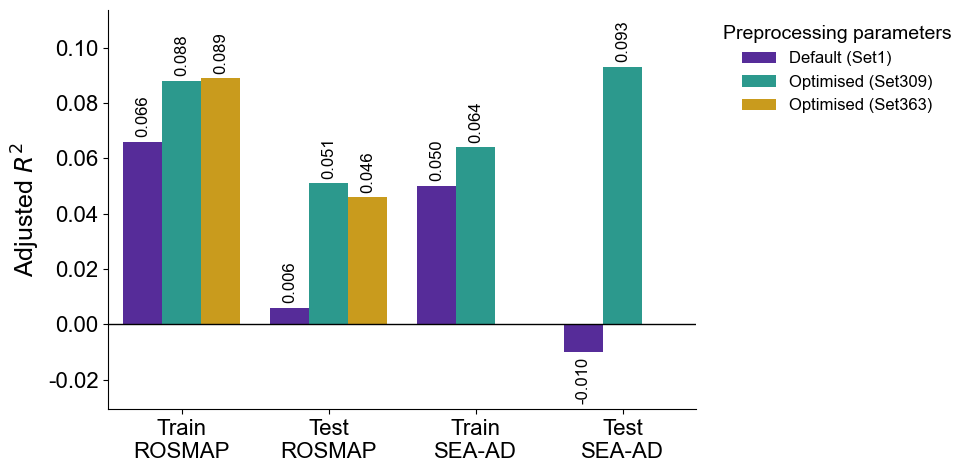

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter

# -----------------------
# Illustrator-friendly text
# -----------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

# -----------------------
# 1) Enter results here
# -----------------------
# Use np.nan for values you do not want plotted / do not have.
# Negative values are allowed.
results = {
    "ROSMAP": {
        "Default (Set1)": {
            "train": 0.066,
            "test": 0.006,
        },
        "Optimised (Set309)": {
            "train": 0.088,
            "test": 0.051,
        },
        "Optimised (Set363)": {
            "train": 0.089,
            "test": 0.046,
        },
    },

    "SEA-AD": {
        "Default (Set1)": {
            "train": 0.050,
            "test": -0.010,
        },
        "Optimised (Set309)": {
            "train": 0.064,
            "test": 0.093,
        },
        "Optimised (Set363)": {
            "train": np.nan,
            "test": np.nan,
        },
    },
}

# -----------------------
# 2) Build dataframe
# -----------------------
rows = []

for dataset, dataset_results in results.items():
    for pipeline_label, vals in dataset_results.items():

        rows.append({
            "group": f"Train\n{dataset}",
            "r2": vals["train"],
            "pipeline": pipeline_label,
            "dataset": dataset,
            "split": "train",
        })

        rows.append({
            "group": f"Test\n{dataset}",
            "r2": vals["test"],
            "pipeline": pipeline_label,
            "dataset": dataset,
            "split": "test",
        })

plot_df = pd.DataFrame(rows)

# Remove missing values so they do not appear as empty bars
plot_df = plot_df.dropna(subset=["r2"]).copy()

# Define order manually
group_order = [
    "Train\nROSMAP",
    "Test\nROSMAP",
    "Train\nSEA-AD",
    "Test\nSEA-AD",
]

pipeline_order = [
    "Default (Set1)",
    "Optimised (Set309)",
    "Optimised (Set363)",
]

plot_df["group"] = pd.Categorical(
    plot_df["group"],
    categories=group_order,
    ordered=True,
)

plot_df["pipeline"] = pd.Categorical(
    plot_df["pipeline"],
    categories=pipeline_order,
    ordered=True,
)

# -----------------------
# 3) Colours
# -----------------------
palette = {
    "Default (Set1)": "#521AAB",
    "Optimised (Set309)": "#1AAB9B",
    "Optimised (Set363)": "#E6A800",
}

# -----------------------
# 4) Plot
# -----------------------
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=plot_df,
    x="group",
    y="r2",
    hue="pipeline",
    order=group_order,
    hue_order=pipeline_order,
    palette=palette,
    dodge=True,
)

# Horizontal zero line, important when negative R² exists
ax.axhline(0, color="black", linewidth=1)

# Dynamic y-limits that allow negative values
y_min = plot_df["r2"].min()
y_max = plot_df["r2"].max()
y_range = y_max - y_min

# Fallback in case values are very similar
if y_range == 0:
    y_range = abs(y_max) if y_max != 0 else 0.1

y_pad = y_range * 0.20

ax.set_ylim(
    min(0, y_min - y_pad),
    y_max + y_pad,
)

# -----------------------
# 5) Value labels
# -----------------------
for p in ax.patches:
    height = p.get_height()

    # Skip weird/invisible patches
    if not np.isfinite(height):
        continue

    # Skip bars that are basically zero if desired
    # Remove this condition if you want to label exact 0.000 bars too
    if abs(height) < 1e-12:
        continue

    if height >= 0:
        label_y = height + y_pad * 0.08
        va = "bottom"
    else:
        label_y = height - y_pad * 0.08
        va = "top"

    ax.text(
        p.get_x() + p.get_width() / 2,
        label_y,
        f"{height:.3f}",
        ha="center",
        va=va,
        fontsize=12,
        rotation=90,
    )

# -----------------------
# 6) Styling
# -----------------------
ax.set_ylabel("Adjusted $R^2$", fontsize=18)
ax.set_xlabel("")

ax.tick_params(axis="x", labelsize=16, rotation=0)
ax.tick_params(axis="y", labelsize=16)

ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    frameon=False,
    title="Preprocessing parameters",
    fontsize=12,
    title_fontsize=14,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
)

plt.tight_layout()

# -----------------------
# 7) Save
# -----------------------
out_dir = r"C:\Users\gabri\Documents\Data_projects\MCcharactertization\ROSMAP\Top_sets\Set309"

plt.savefig(
    os.path.join(out_dir, "TOPsets_ROSMAP_SEAAD_vsDef.pdf"),
    dpi=300,
    bbox_inches="tight",
)

plt.show()